<a href="https://colab.research.google.com/github/yugan243/Data-Aug-Oxford-17-Flower-Dataset/blob/main/Assignment_01_Data_Augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 01 - Data Augmentation on Oxford 17 Category Flower Dataset

## 0. Setup the Environment

In [34]:
# Mount the google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
# imports
import os, shutil
import random
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.nn as nn
import copy
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from torch.utils.data import ConcatDataset
import time

!pip -q install torchinfo
from torchinfo import summary


In [36]:
SRC = '/content/drive/MyDrive/Semester 7/Advanced Machine Learning/Data Augmentation Assignment/data'
DST = '/content/drive/MyDrive/Semester 7/Advanced Machine Learning/Data Augmentation Assignment/ImageFolder'

## 1. Data Loading

In [37]:
# Data Loading into Sub Folders
class_ranges = {
    'Daffodil': (1, 80),
    'Iris': (401, 480),
    'Tulip': (561, 640),
    'Sunflower': (721, 800),
    'Daisy': (801, 880)
}

for cls, (start, end) in class_ranges.items():
    cls_dir = os.path.join(DST, cls)
    os.makedirs(cls_dir, exist_ok=True)
    for i in range(start, end + 1):
        fname = f"image_{i:04d}.jpg"
        shutil.copy(os.path.join(SRC, fname), cls_dir)


#### 1.1 Verification

In [38]:
# Count Check

total = 0
for cls in sorted(os.listdir(DST)):
    n = len(os.listdir(os.path.join(DST, cls)))
    print(f"{cls:10s}: {n}")
    total += n
print("Total:", total)   # should be 400

Daffodil  : 80
Daisy     : 80
Iris      : 80
Sunflower : 80
Tulip     : 80
Total: 400


Total of 400 images loaded successfully into sub folders. 80 from each class

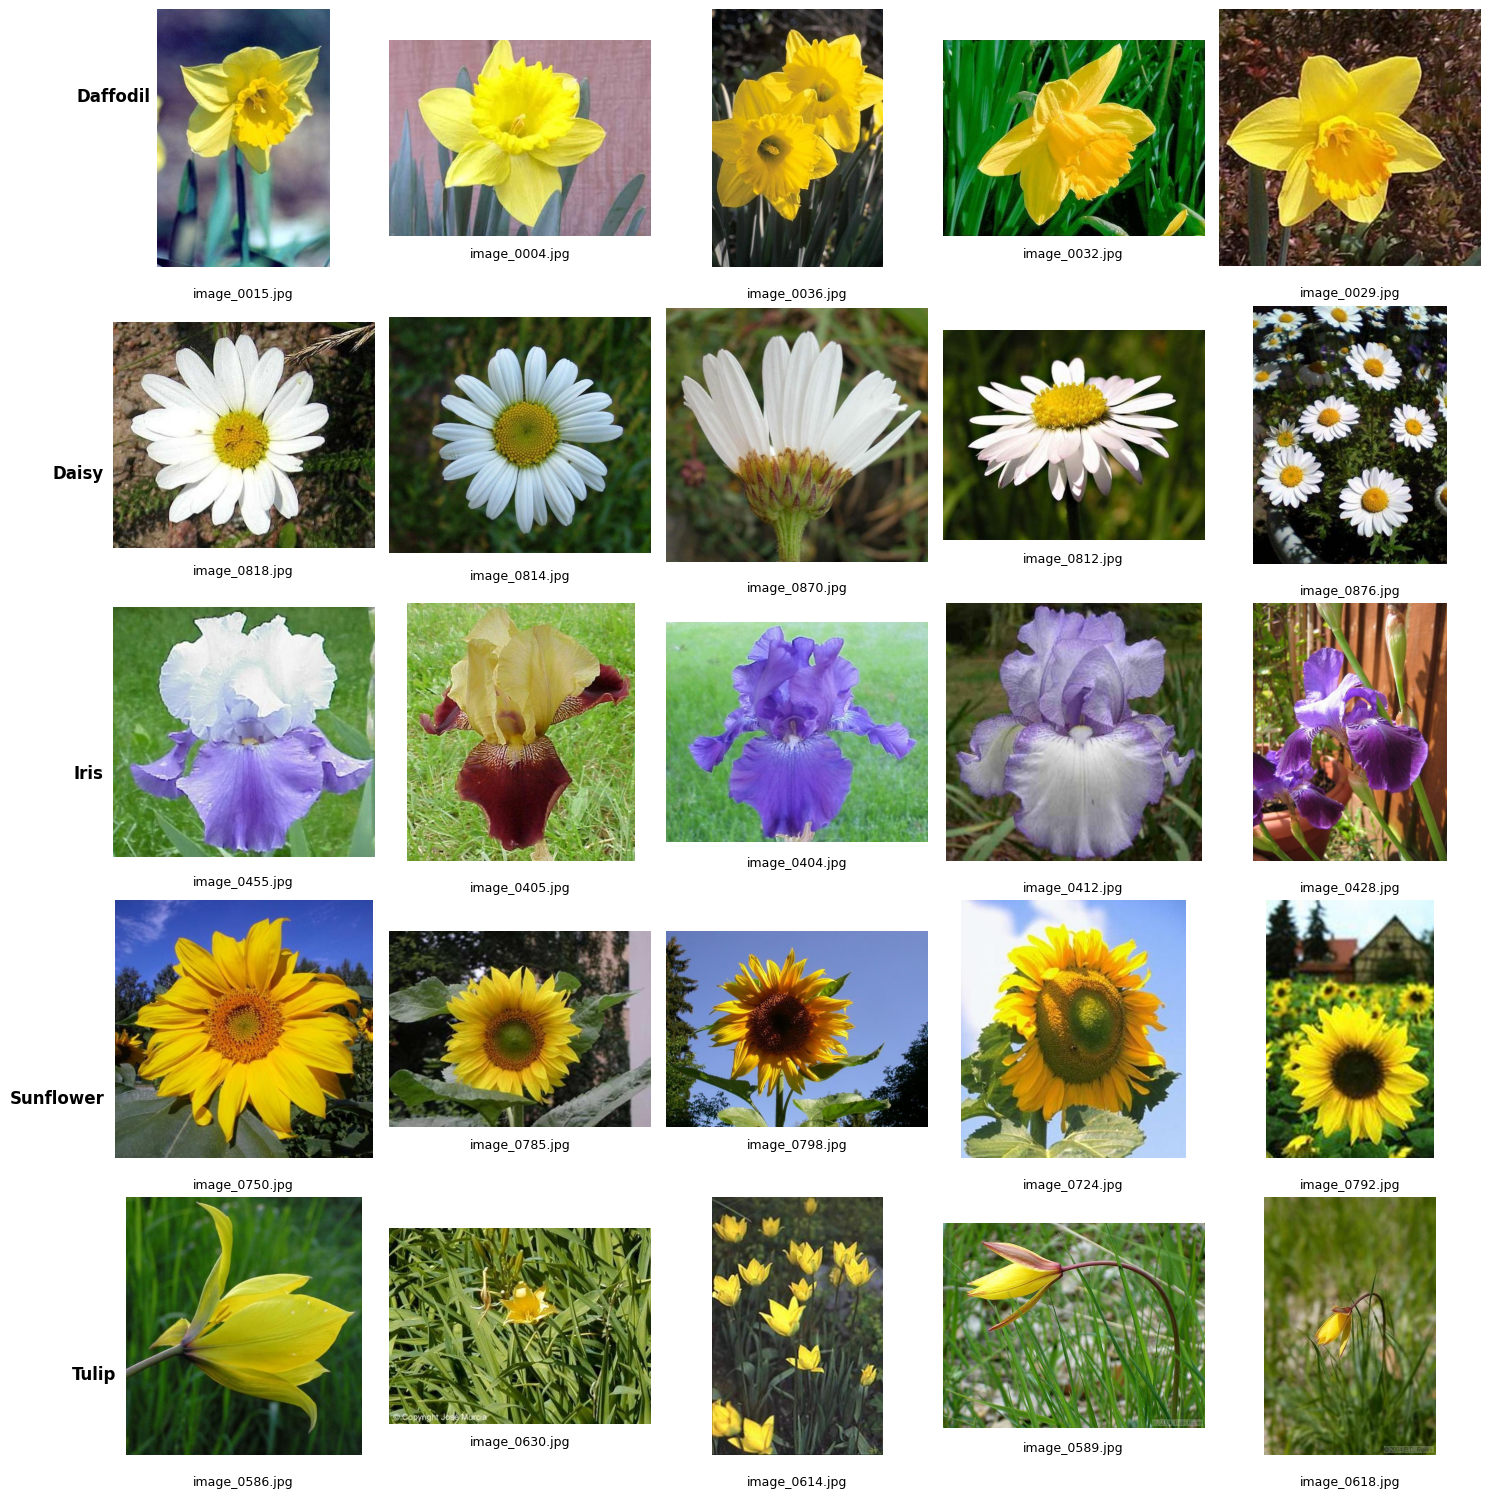

In [39]:
# Visual Check

# Set the global seed
SEED = 42
random.seed(SEED); np.random.seed(SEED); _ = torch.manual_seed(SEED)
classes = sorted(os.listdir(DST))
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 15))
for r, cls in enumerate(classes):
    files = random.sample(sorted(os.listdir(os.path.join(DST, cls))), 5)
    for c, f in enumerate(files):
        img = Image.open(os.path.join(DST, cls, f))
        axes[r, c].imshow(img)
        axes[r, c].axis('off')
        axes[r, c].set_title(f, fontsize=9, y=-0.15)
    axes[r, 0].text(-20, img.size[1]//2, cls, weight='bold', va='center', ha='right', fontsize=12)
plt.tight_layout()
plt.show()

Compared the sample grid above with the class figure on the Oxford 17 Category
Flower Dataset page. (https://www.robots.ox.ac.uk/~vgg/data/flowers/17/)

Daffodil images range from 0001 to 0080. And they can be identified from ***yellow trumpet-shaped centre***. (e.g. image_0015.jpg, image_0032.jpg)

Iris images range from 0401 to 0480 and those are the flowers with ***purple petals with yellow markings also some comes with different colors as well like blue, reddish yellow***. (e.g. image_0404.jpg, image_0455.jpg)

Tulips are in the range of 0561-0640 and they are the ones having ***cup-shaped petals***. Most of the tulip images have the leaves of them in the background.(e.g. image_0589.jpg, image_0614.jpg)

Sunflowers are in the range of 0721-0800 and they can be identified uniquely with the ***large dark centre disc***. This Dark cetre sometimes more towards to black while sometimes towards to dark yellow. (e.g. image_0792.jpg, image_0798.jpg)

Finally Daisy flowers are in the range of 0801-0880. And could  be identified with ***white petals around a yellow circular center***. (e.g. image_0818.jpg, image_0814.jpg)

Some images contain several flowers, Some images are close-ups while others are wide shots. It seems like sometimes the background can be busy with leaves, ground, soil etc.. And also those images have different sizes and different aspect ratios.

As a conclusion all these five ranges match their class names

## 2. Data Splitting

In [40]:
# Set the global seed
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [41]:
# Build a sorted list of the images

records = []
for cls in sorted(os.listdir(DST)):
    for f in sorted(os.listdir(os.path.join(DST, cls))):
        records.append({'path': os.path.join(cls, f), 'class': cls})

df = pd.DataFrame(records)
class_to_idx = {c: i for i, c in enumerate(sorted(df['class'].unique()))}
df['label'] = df['class'].map(class_to_idx)
print(class_to_idx)

{'Daffodil': 0, 'Daisy': 1, 'Iris': 2, 'Sunflower': 3, 'Tulip': 4}


In [42]:
# Split the dataset or load the saved split if it already exists

SPLIT_DIR = os.path.join(os.path.dirname(DST), 'splits')
os.makedirs(SPLIT_DIR, exist_ok=True)

HOLDOUT_FRAC = 0.3
VAL_OF_HOLDOUT  = 0.5

if os.path.exists(os.path.join(SPLIT_DIR, 'train.csv')):
    print("Loading existing split")
    train_df = pd.read_csv(os.path.join(SPLIT_DIR, 'train.csv'))
    val_df   = pd.read_csv(os.path.join(SPLIT_DIR, 'val.csv'))
    test_df  = pd.read_csv(os.path.join(SPLIT_DIR, 'test.csv'))
else:
    print("Creating new split")
    train_df, test_val_df = train_test_split(
        df, test_size=HOLDOUT_FRAC, stratify=df['label'], random_state=SEED)
    test_df, val_df = train_test_split(
        test_val_df, test_size=VAL_OF_HOLDOUT, stratify=test_val_df['label'], random_state=SEED)

    train_df.to_csv(os.path.join(SPLIT_DIR, 'train.csv'), index=False)
    test_df.to_csv(os.path.join(SPLIT_DIR, 'test.csv'), index=False)
    val_df.to_csv(os.path.join(SPLIT_DIR, 'val.csv'), index=False)

Loading existing split


In [43]:
# Check the Split

# Sizes
print(len(train_df), len(val_df), len(test_df))

# Class balance per split (should be equal or nearly equal)
all_splits = pd.concat([train_df.assign(split='train'),
                        val_df.assign(split='val'),
                        test_df.assign(split='test')])
print(pd.crosstab(all_splits['class'], all_splits['split']))

# No leakage: no image appears in two sets
assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path)
assert set(val_df.path).isdisjoint(test_df.path)

280 60 60
split      test  train  val
class                      
Daffodil     12     56   12
Daisy        12     56   12
Iris         12     56   12
Sunflower    12     56   12
Tulip        12     56   12


*   There are only 400 original data. And only 80 per each class.
Chose the 70/15/15 split because training needs enough examples to learn and validation needs enough to pick the best model reliably. Also test needs enough data to give a trustworthy score. So from this plit training set receives 280 samples and test and validation receives 60 samples for each. That's a good split for this kind of a situation. Also considered the 80/10/10 split and 60/20/20 split as well. Both of them rejected.

*    80/10/10 rejected because it would give more data to train (320 samples) but lesser for each validation and testing splits. With an 80/10/10 split, the test set would have only 40 images, so each misclassification changes accuracy by 2.5%. In the ablation experiments, the differences between augmentation settings may be only 2.5%, which is just 1 image, and that could happen by chance. With 70/15/15, each test image is worth 1.67%, which gives a finer measurement, while still leaving 280 images ( 56 per class) for training.

*    60/20/20 rejected because it has not much data to train a model. only 240 will receive as the train data.(48 per class) but has more validation and test data.

*    So the best split for this scenario is 70/15/15.

*    stratification gives exactly 56/12/12 per class, so every set keeps the same class balance

*    Validation and Test sets are kept separate. Validation is picking the best epoch while the test set kept untouched because we need a honest final score.

*    The split is reproducible because I have set a fixed seed, a sorted file list, and CSV files saved to Drive.


## 3. Preprocessing

In [44]:
# Initialize a Pytorch Dataset to load the data

class FlowerDataset(Dataset):
    def __init__(self, df, root, transform=None):
        self.df = df.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return  len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(os.path.join(self.root, row['path'])).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, int(row['label'])

In [45]:
# Compute the mean and std from the training set

# Resize + scale to [0,1] only (no Normalize yet: we don't know mean/std!)
stats_tf = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
])

stats_ds = FlowerDataset(train_df, DST, transform=stats_tf)
train_imgs = torch.stack([stats_ds[i][0] for i in range(len(stats_ds))])
print(train_imgs.shape)

mean = train_imgs.mean(dim=(0,2,3))
std  = train_imgs.std(dim=(0,2,3))
print("mean:", mean)
print("std :", std)

torch.Size([280, 3, 96, 96])
mean: tensor([0.4300, 0.4272, 0.2723])
std : tensor([0.2816, 0.2527, 0.2538])


In [46]:
# Final transform and the three datasets
LOCAL = '/content/ImageFolder'
if not os.path.exists(LOCAL):
    shutil.copytree(DST, LOCAL)

base_tf = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

train_ds = FlowerDataset(train_df, LOCAL, transform=base_tf)
val_ds   = FlowerDataset(val_df, LOCAL, transform=base_tf)
test_ds  = FlowerDataset(test_df, LOCAL, transform=base_tf)

In [47]:
# Sanity checks

x, y = train_ds[0]
print("shape:", x.shape, "label:", y, type(y))      # expect torch.Size([3, 96, 96]), int

# After normalising, the training set should be ~mean 0, ~std 1 per channel
norm_imgs = torch.stack([train_ds[i][0] for i in range(len(train_ds))])
print("per-channel mean:", norm_imgs.mean(dim=(0, 2, 3)))
print("per-channel std :", norm_imgs.std(dim=(0, 2, 3)))

shape: torch.Size([3, 96, 96]) label: 1 <class 'int'>
per-channel mean: tensor([-2.3615e-07,  7.3860e-07, -1.5299e-07])
per-channel std : tensor([1., 1., 1.])


- In the preprocessing step, all images are resized to **96 × 96 pixels** so that they have the same dimensions and can be stacked into batches and processed by a CNN. This also reduces computational cost. A direct resize is used because it forces every image to the required dimensions and keeps the whole flower in the frame, although it may cause slight distortion if the original aspect ratios differ.

- Every image is converted to **three colour channels: Red, Green, and Blue (RGB)**. This ensures a consistent input format for the model.

- The `ToTensor()` transformation scales pixel values from **[0, 255] to [0, 1]** by dividing them by 255. Standardisation is then applied to make the input values more consistent, which can help the model converge more effectively during training.

- The mean and standard deviation are calculated using the training images only. The calculated RGB mean values are **[0.4300, 0.4272, 0.2723]**, and the standard deviation values are **[0.2816, 0.2527, 0.2538]**. These statistics are then used to standardise the training, validation, and test images. Using only training statistics prevents data leakage because information from the validation and test sets is not used to determine the preprocessing parameters.

- **One-hot encoding is unnecessary** because `CrossEntropyLoss` expects integer class labels rather than one-hot vectors. The model outputs raw logits for each class, and `CrossEntropyLoss` internally applies the equivalent of `LogSoftmax` followed by `NLLLoss`.

## 4. The baseline Classifier


In [48]:
# Use the GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [49]:
# Training settings
BATCH_SIZE   = 32
EPOCHS       = 50
LR           = 0.001
WEIGHT_DECAY = 0.0001

### 4.1 Define the CNN model

In [50]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),                     # halves height & width
    )

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # global average pooling -> 1x1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [51]:
summary(BaselineCNN().to(device), input_size=(1, 3, 96, 96))

Layer (type:depth-idx)                   Output Shape              Param #
BaselineCNN                              [1, 5]                    --
├─Sequential: 1-1                        [1, 256, 6, 6]            --
│    └─Sequential: 2-1                   [1, 32, 48, 48]           --
│    │    └─Conv2d: 3-1                  [1, 32, 96, 96]           896
│    │    └─BatchNorm2d: 3-2             [1, 32, 96, 96]           64
│    │    └─ReLU: 3-3                    [1, 32, 96, 96]           --
│    │    └─MaxPool2d: 3-4               [1, 32, 48, 48]           --
│    └─Sequential: 2-2                   [1, 64, 24, 24]           --
│    │    └─Conv2d: 3-5                  [1, 64, 48, 48]           18,496
│    │    └─BatchNorm2d: 3-6             [1, 64, 48, 48]           128
│    │    └─ReLU: 3-7                    [1, 64, 48, 48]           --
│    │    └─MaxPool2d: 3-8               [1, 64, 24, 24]           --
│    └─Sequential: 2-3                   [1, 128, 12, 12]          --
│    │   

### 4.2 Define the training functions

In [52]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


# train funtion

def train_model(train_ds, val_ds, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    model = BaselineCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  generator=g, num_workers=2)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
        }

    best_acc, best_loss, best_epoch, best_state = -1, float('inf'), 0, None

    for epoch in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(history, (tl, ta, vl, va)):
            history[k].append(v)

        # keep the best model on VALIDATION
        if va > best_acc or (va == best_acc and vl < best_loss):
            best_acc, best_loss, best_epoch = va, vl, epoch
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(f"Epoch {epoch:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    model.load_state_dict(best_state)
    print(f"Best val acc {best_acc:.3f} at epoch {best_epoch}")
    return model, history, best_epoch

### 4.3 Train the model

In [53]:
baseline_model, baseline_hist, baseline_best = train_model(train_ds, val_ds)

Epoch 01 | train loss 1.194 acc 0.507 | val loss 1.304 acc 0.450
Epoch 02 | train loss 0.851 acc 0.657 | val loss 1.168 acc 0.533
Epoch 03 | train loss 0.731 acc 0.736 | val loss 0.734 acc 0.700
Epoch 04 | train loss 0.671 acc 0.746 | val loss 0.722 acc 0.750
Epoch 05 | train loss 0.590 acc 0.764 | val loss 0.792 acc 0.733
Epoch 06 | train loss 0.593 acc 0.761 | val loss 0.700 acc 0.717
Epoch 07 | train loss 0.544 acc 0.789 | val loss 0.648 acc 0.733
Epoch 08 | train loss 0.543 acc 0.804 | val loss 0.670 acc 0.733
Epoch 09 | train loss 0.467 acc 0.829 | val loss 0.622 acc 0.750
Epoch 10 | train loss 0.450 acc 0.825 | val loss 0.565 acc 0.750
Epoch 11 | train loss 0.380 acc 0.861 | val loss 0.622 acc 0.750
Epoch 12 | train loss 0.353 acc 0.893 | val loss 0.671 acc 0.667
Epoch 13 | train loss 0.310 acc 0.875 | val loss 0.746 acc 0.700
Epoch 14 | train loss 0.304 acc 0.893 | val loss 0.634 acc 0.733
Epoch 15 | train loss 0.306 acc 0.904 | val loss 1.041 acc 0.600
Epoch 16 | train loss 0.3

### 4.4 Plot the Curves

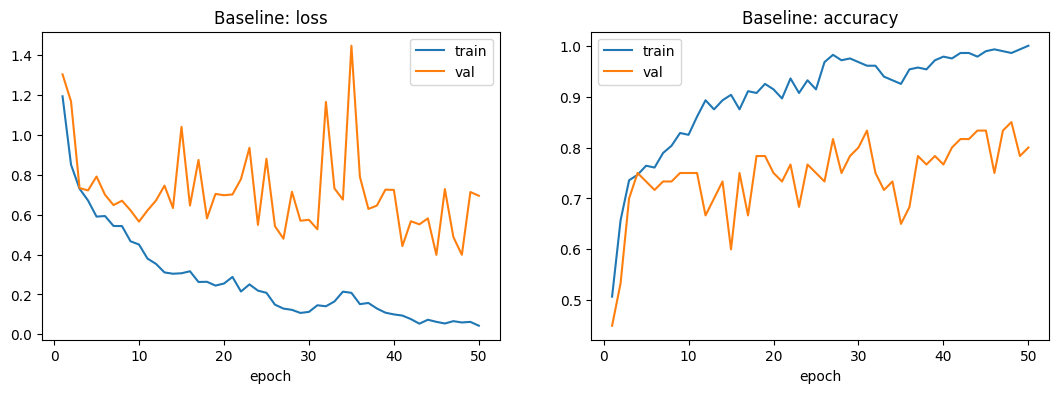

In [54]:
# Plot Accuracy and Loss curves
def plot_history(h, title):
    ep = range(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    # Loss curves
    ax[0].plot(ep, h['train_loss'], label='train')
    ax[0].plot(ep, h['val_loss'], label='val')
    ax[0].set_title(f'{title}: loss')
    ax[0].set_xlabel('epoch')
    ax[0].legend()

    # Accuracy curves
    ax[1].plot(ep, h['train_acc'], label='train')
    ax[1].plot(ep, h['val_acc'], label='val')
    ax[1].set_title(f'{title}: accuracy')
    ax[1].set_xlabel('epoch')
    ax[1].legend()

    plt.show()

plot_history(baseline_hist, 'Baseline')

### 4.5 Test set Evaluation

Test accuracy: 0.8166666666666667
Macro F1     : 0.8065021645021645

Classification Report:
              precision    recall  f1-score   support

    Daffodil       0.80      0.67      0.73        12
       Daisy       0.75      1.00      0.86        12
        Iris       0.92      0.92      0.92        12
   Sunflower       0.92      1.00      0.96        12
       Tulip       0.67      0.50      0.57        12

    accuracy                           0.82        60
   macro avg       0.81      0.82      0.81        60
weighted avg       0.81      0.82      0.81        60



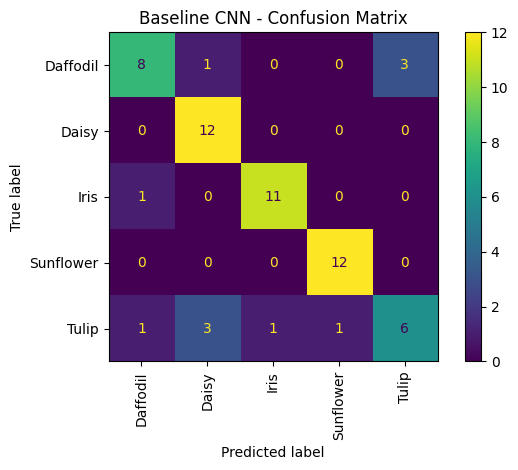

In [55]:
def evaluate(model, ds):
    loader = DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model.eval()
    preds, labels = [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)

            outputs = model(x)
            predictions = outputs.argmax(dim=1)

            preds.append(predictions.cpu())
            labels.append(y)

    return torch.cat(labels).numpy(), torch.cat(preds).numpy()


# Evaluate the baseline model on the test dataset
y_true, y_pred = evaluate(baseline_model, test_ds)

# Get flower class names
class_names = list(class_to_idx.keys())

# Print evaluation metrics
print("Test accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1     :", f1_score(y_true, y_pred, average="macro"))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation="vertical"
)

plt.title("Baseline CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

### Task 4: Baseline Discussion

1. Architecture

    *   4 conv blocks have been used as follows:- ** Conv 3×3 → BatchNorm → ReLU → MaxPool. Channels 32 → 64 → 128 → 256; image size 96 → 48 → 24 → 12 → 6.**
    *   Global average pooling has been used and Dropout is set to 0.5. Finally flattened layer mapping to 5 outputs using Linear(256 → 5).
    *   390,661 parameters, 295K of them in the last conv block.
    *   Why? small dataset (280 images), so a small model to limit overfitting. 3×3 kernels are efficient. Channels double as size halves to keep the cost balanced. BatchNorm for stable training. Global average pooling instead of a large dense layer means far fewer parameters. Dropout reduces overfitting.

2. Training settings

    *   Adam (adaptive steps, little tuning needed)
    *   LR 0.001 (Adam’s standard default)
    *   batch size 32 (about 9 steps per epoch; noise acts as mild regularisation)
    *   weight decay 1e-4 (mild penalty on large weights)
    *   50 epochs (best epoch kept, so training longer does no harm)
    *  CrossEntropyLoss (multi-class, integer labels).

3. Training curves

    Training accuracy reaches 100% with training loss at 0.043 by epoch 50 while
    Validation accuracy fluctuates around 75–85%, and validation loss doesn’t keep falling.The gap opens around epoch 10, which means overfitting. This motivates augmentation. Validation is noisy because each of the 60 images is worth 1.67%.

4. Evaluation metric

    The classes are balanced (12 test images each), so accuracy is fair.
    Macro F1 and the confusion matrix show per-class behaviour.

5. Model selection

    The weights from the epoch with the best validation accuracy (85.0%, epoch 48; ties broken by lower validation loss) were restored.The test set was used once.
    The best-epoch validation score is optimistic, since it’s the maximum of 50 noisy values.

6. Results

    Test accuracy 81.7%, macro F1 0.807.
    Per-class F1: Sunflower 0.96, Iris 0.92, Daisy 0.86, Daffodil 0.73, Tulip 0.57 (weakest; recall 0.50, so only 6 of 12 correct).
    According to the confusion matrix, the Model sometimes hard to distinguish the Tulips and Daffodils. (3 Tulips are identified as Daffodils and 1 Daffodil is identified as a Tulip. This could be because of their appearance seems to be close.)
    Over 3 seeds (Task 7), the baseline is 82.2 ± 2.5%, so a single run can vary by about ±2.5%.

## 5. Image Augmentation

### 5.1 Augmentation Policies

In [56]:
AUG_LOCAL = '/content/augmented'
AUG_DRIVE = os.path.join(os.path.dirname(DST), 'augmented')

AUG_POLICIES = {
    'flip':   transforms.RandomHorizontalFlip(p=1.0),
    'rotate': transforms.RandomRotation(degrees=20),
    'crop':   transforms.RandomResizedCrop(size=96, scale=(0.7, 1.0)),
    'color':  transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.0),
    'blur':   transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5)),
}

# A combined policy: randomly mixes the techniques above
AUG_POLICIES['combined'] = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([AUG_POLICIES['rotate']], p=0.5),
    transforms.RandomApply([AUG_POLICIES['crop']],   p=0.5),
    transforms.RandomApply([AUG_POLICIES['color']],  p=0.5),
    transforms.RandomApply([AUG_POLICIES['blur']],   p=0.3),
])

### 5.2 Generator Function

In [57]:
resize96 = transforms.Resize((96, 96))

def generate_augmented(name, policy, copies, seed=SEED):
    """Create `copies` augmented versions of every TRAINING image. Returns (folder, DataFrame)."""
    torch.manual_seed(seed); random.seed(seed)            # reproducible augmentations
    out_root = os.path.join(AUG_LOCAL, f'{name}_x{copies}')
    records = []
    for _, row in train_df.iterrows():                     # TRAIN ONLY: never val/test
        img = Image.open(os.path.join(LOCAL, row['path'])).convert('RGB')
        stem = os.path.splitext(os.path.basename(row['path']))[0]   # e.g. image_0015
        os.makedirs(os.path.join(out_root, row['class']), exist_ok=True)
        for k in range(copies):
            aug = resize96(policy(img))
            rel = os.path.join(row['class'], f'{stem}_{name}_{k+1}.jpg')
            aug.save(os.path.join(out_root, rel), quality=95)
            records.append({'path': rel, 'class': row['class'], 'label': row['label']})
    aug_df = pd.DataFrame(records)
    aug_df.to_csv(os.path.join(out_root, 'aug_list.csv'), index=False)
    return out_root, aug_df

### 5.3 Build the Main Augmented Training Set

In [58]:
MAIN_COPIES = 2        #2 -> ratio 1:2 -> 280 original + 560 augmented = 840

main_dir, main_aug_df = generate_augmented('combined', AUG_POLICIES['combined'], MAIN_COPIES)

aug_only_ds   = FlowerDataset(main_aug_df, main_dir, transform=base_tf)   # same mean/std as Task 3
train_aug_ds  = ConcatDataset([train_ds, aug_only_ds])                    # originals + augmented
print(len(train_ds), "+", len(aug_only_ds), "=", len(train_aug_ds))

280 + 560 = 840


### 5.4 Statistics on the final augmented training set

In [59]:
stats = pd.DataFrame({
    'original':  train_df['class'].value_counts().sort_index(),
    'augmented': main_aug_df['class'].value_counts().sort_index(),
})
stats['total'] = stats['original'] + stats['augmented']
stats.loc['TOTAL'] = stats.sum()
print(stats)
print("Ratio original : augmented = 1 :", MAIN_COPIES)

           original  augmented  total
class                                
Daffodil         56        112    168
Daisy            56        112    168
Iris             56        112    168
Sunflower        56        112    168
Tulip            56        112    168
TOTAL           280        560    840
Ratio original : augmented = 1 : 2


### 5.5 original vs. augmented, for each class and technique

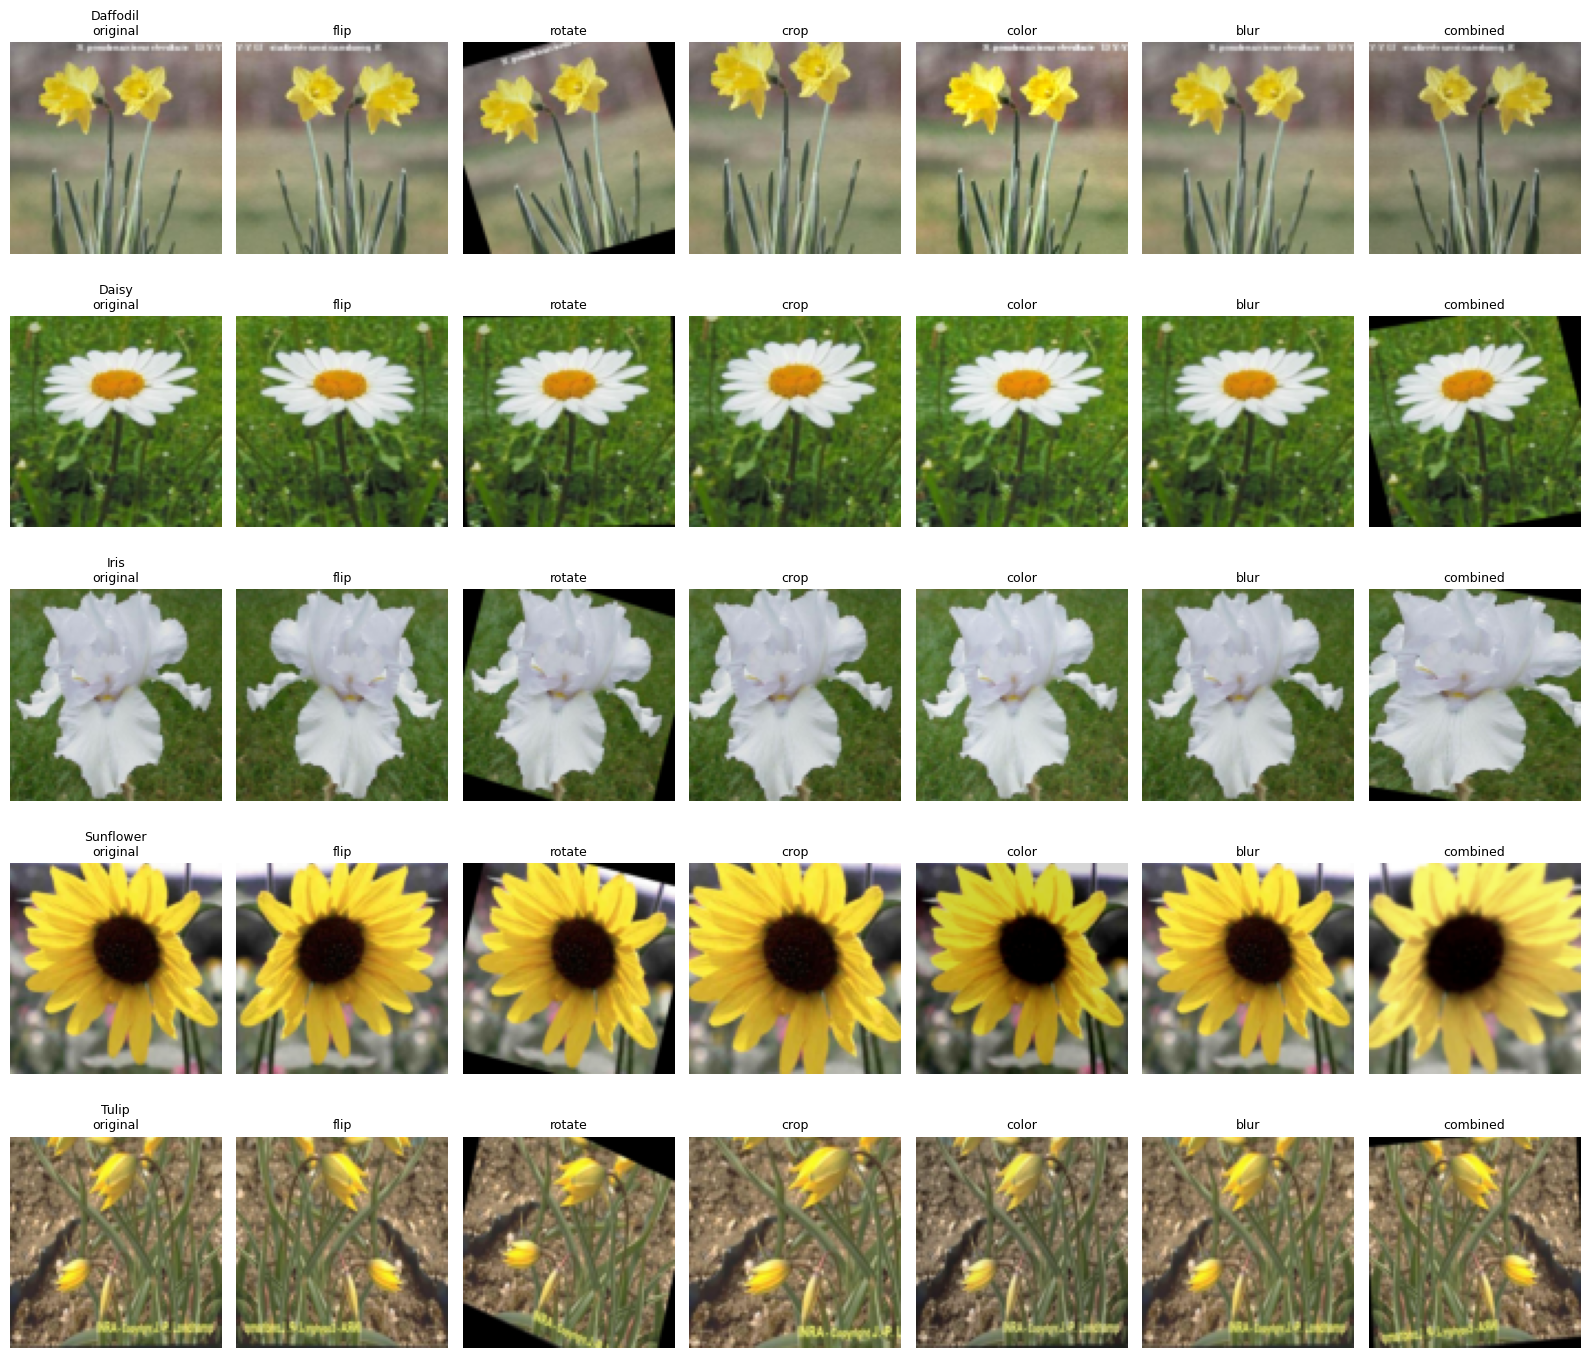

In [60]:
techniques = ['flip', 'rotate', 'crop', 'color', 'blur', 'combined']
torch.manual_seed(SEED)
fig, axes = plt.subplots(len(class_names), len(techniques) + 1, figsize=(16, 14))
for r, cls in enumerate(class_names):
    row = train_df[train_df['class'] == cls].iloc[0]
    img = Image.open(os.path.join(LOCAL, row['path'])).convert('RGB')
    axes[r, 0].imshow(resize96(img)); axes[r, 0].set_title(f'{cls}\noriginal', fontsize=9)
    for c, t in enumerate(techniques, start=1):
        axes[r, c].imshow(resize96(AUG_POLICIES[t](img)))
        axes[r, c].set_title(t, fontsize=9)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

### Task 5: augmentation discussion

1. Strategy

    *  Offline augmentation: new image files are generated and saved, which is needed for Deliverable 2 and makes experiments repeatable.
    *  Training split only. Validation and test stay real, unmodified images.
    *  The same normalisation (Task 3 mean and std) is used for fairness.

2. Techniques and Values, with Justification for Label Preservation

| Technique | Value | What it Simulates and Why the Label Is Preserved |
|---|---|---|
| Horizontal flip | `p = 1.0` | Simulates viewing the flower as a mirror image. The flower's identity generally remains unchanged after horizontal flipping. |
| Rotation | `±20°` | Simulates slight camera tilts. The limited rotation preserves the flower's overall structure while introducing orientation variation. |
| Random resized crop | `scale = 0.7–1.0` | Simulates close-up and wider views, reflecting the variation observed in Task 1. The range retains a substantial portion of the flower, helping preserve its identifying features. |
| Colour jitter | Brightness, contrast, saturation = `0.3`; **hue = 0** | Simulates outdoor lighting and exposure variations. Hue is kept unchanged because flower colour can be an important class-discriminating feature. |
| Gaussian blur | Kernel size = `5`, `σ = 0.1–1.5` | Simulates mild focus variations. The limited blur introduces image-quality variation while aiming to retain important flower structures. |
| Combined augmentation | Flip = `0.5`, rotation = `0.5`, crop = `0.5`, colour jitter = `0.5`, blur = `0.3` | Applies a random combination of augmentations to simulate realistic variations in orientation, framing, lighting, and focus while aiming to preserve the flower's identity. |



   *   No vertical flip: flowers grow upright, so upside-down images are unrealistic.
 *   The values were checked visually in the grid to make sure the images still look like real flowers.

3. Statistics of the final set

    *   Ratio 1:2: 56 original + 112 augmented = 168 per class; 280 + 560 = 840 total. Class balance is kept.
    *   Every file is named after its source (e.g. image_0015_combined_1.jpg), so it’s traceable.

4. Sample grid is also shown in the previous step and clearly shows the original image, same image with each individual augmentations applied, and with combined augmentations applied

### 5.6 Save to Drive

In [61]:
shutil.copytree(AUG_LOCAL, AUG_DRIVE, dirs_exist_ok=True)
print("Saved to:", AUG_DRIVE)

Saved to: /content/drive/MyDrive/Semester 7/Advanced Machine Learning/Data Augmentation Assignment/augmented


## 6. Retraining on the Augmented set

In [62]:
# Define a results table

results = []

def record_result(name, train_set, n_aug, hist, best_epoch, y_true, y_pred):
    results.append({
        'experiment':    name,
        'train_size':    len(train_set),        # original + augmented
        'n_original':    len(train_ds),
        'n_augmented':   n_aug,
        'best_epoch':    best_epoch,
        'best_val_acc':  max(hist['val_acc']),
        'test_acc':      accuracy_score(y_true, y_pred),
        'test_macro_f1': f1_score(y_true, y_pred, average='macro'),
    })
    return pd.DataFrame(results)

# add baseline that previously trained
record_result('Baseline (no aug)', train_ds, 0, baseline_hist, baseline_best, y_true, y_pred)

,experiment,train_size,n_original,n_augmented,best_epoch,best_val_acc,test_acc,test_macro_f1
0,Baseline (no aug),280,280,0,48,0.85,0.816667,0.806502


Epoch 01 | train loss 1.029 acc 0.598 | val loss 0.825 acc 0.700
Epoch 02 | train loss 0.746 acc 0.738 | val loss 0.746 acc 0.667
Epoch 03 | train loss 0.629 acc 0.757 | val loss 0.663 acc 0.733
Epoch 04 | train loss 0.601 acc 0.763 | val loss 0.634 acc 0.767
Epoch 05 | train loss 0.590 acc 0.760 | val loss 0.545 acc 0.783
Epoch 06 | train loss 0.543 acc 0.799 | val loss 0.568 acc 0.733
Epoch 07 | train loss 0.461 acc 0.826 | val loss 0.504 acc 0.800
Epoch 08 | train loss 0.408 acc 0.855 | val loss 0.506 acc 0.800
Epoch 09 | train loss 0.427 acc 0.827 | val loss 0.687 acc 0.733
Epoch 10 | train loss 0.377 acc 0.861 | val loss 0.485 acc 0.783
Epoch 11 | train loss 0.325 acc 0.886 | val loss 0.470 acc 0.817
Epoch 12 | train loss 0.326 acc 0.877 | val loss 0.568 acc 0.833
Epoch 13 | train loss 0.283 acc 0.901 | val loss 0.673 acc 0.783
Epoch 14 | train loss 0.234 acc 0.915 | val loss 0.763 acc 0.667
Epoch 15 | train loss 0.242 acc 0.915 | val loss 0.945 acc 0.717
Epoch 16 | train loss 0.2

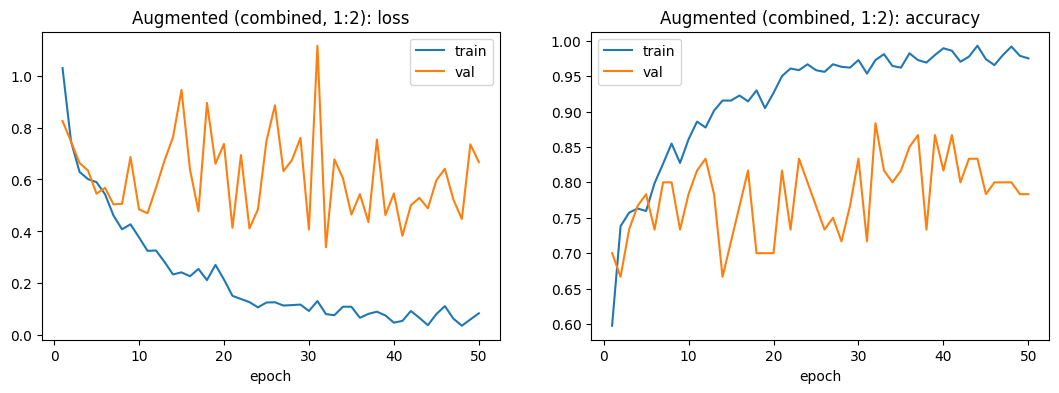

In [63]:
# Retraain on the augmeted set
aug_model, aug_hist, aug_best = train_model(train_aug_ds, val_ds)
plot_history(aug_hist, 'Augmented (combined, 1:2)')

              precision    recall  f1-score   support

    Daffodil       0.77      0.83      0.80        12
       Daisy       0.92      1.00      0.96        12
        Iris       0.92      0.92      0.92        12
   Sunflower       1.00      1.00      1.00        12
       Tulip       0.90      0.75      0.82        12

    accuracy                           0.90        60
   macro avg       0.90      0.90      0.90        60
weighted avg       0.90      0.90      0.90        60



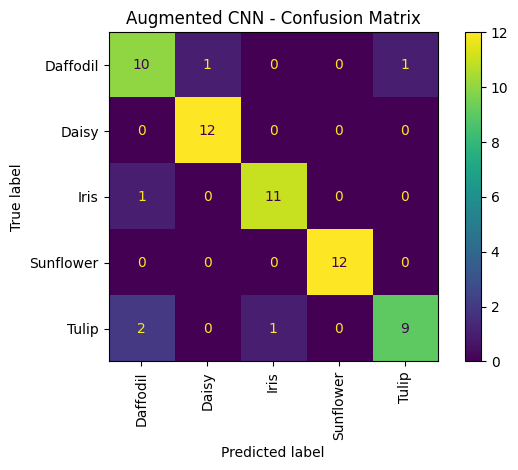

,experiment,train_size,n_original,n_augmented,best_epoch,best_val_acc,test_acc,test_macro_f1
0,Baseline (no aug),280,280,0,48,0.850000,0.816667,0.806502
1,Combined aug (1:2),840,280,560,32,0.883333,0.900000,0.898970


In [64]:
# Evaluate on the same test set

y_true_aug, y_pred_aug = evaluate(aug_model, test_ds)

print(classification_report(y_true_aug, y_pred_aug, target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true_aug, y_pred_aug,
                                        display_labels=class_names, xticks_rotation='vertical')
plt.title('Augmented CNN - Confusion Matrix'); plt.tight_layout(); plt.show()

record_result('Combined aug (1:2)', train_aug_ds, len(aug_only_ds),
              aug_hist, aug_best, y_true_aug, y_pred_aug)

,experiment,train_size,n_original,n_augmented,best_epoch,best_val_acc,test_acc,test_macro_f1
0,Baseline (no aug),280,280,0,48,0.850000,0.816667,0.806502
1,Combined aug (1:2),840,280,560,32,0.883333,0.900000,0.898970


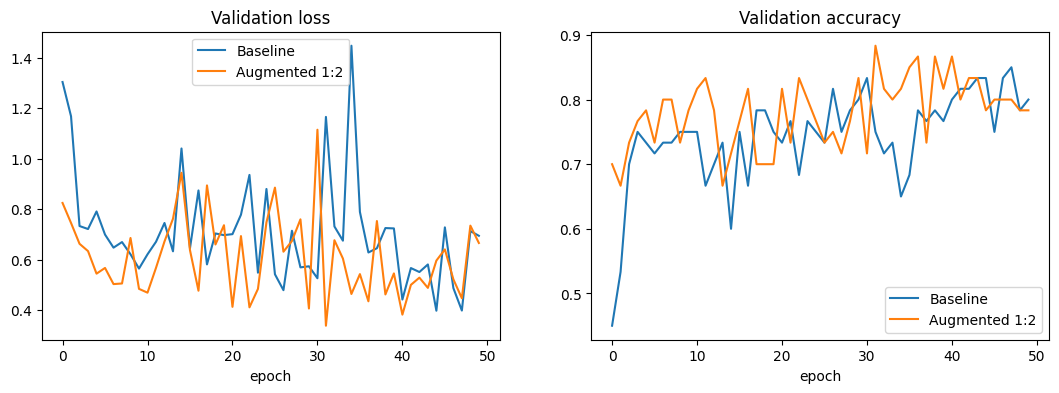

In [65]:
# Side by side comparison

display(pd.DataFrame(results))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, label in [(baseline_hist, 'Baseline'), (aug_hist, 'Augmented 1:2')]:
    ax[0].plot(h['val_loss'], label=label)
    ax[1].plot(h['val_acc'],  label=label)
ax[0].set_title('Validation loss'); ax[1].set_title('Validation accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.show()

### Task 6: retraining discussion


| Metric | Baseline CNN | Augmented CNN (1:2) |
|---|---:|---:|
| Training set size | 280 images | 840 images |
| Best validation accuracy (epoch) | 85.0% (48) | 88.3% (32) |
| **Test accuracy** | **81.7%** | **90.0% (+8.3 percentage points)** |
| **Macro F1-score** | 0.807 | **0.899** |

    *  Same settings, same validation and test sets. Only the training data changed.
    *  Less overfitting: training accuracy peaks around 97–99% rather than 100%, and validation loss reaches lower values (as low as 0.34).
    *  Per-class F1, baseline → augmented: Tulip 0.57 → 0.82 (the biggest gain), Daffodil 0.73 → 0.80, Daisy 0.86 → 0.96, Sunflower 0.96 → 1.00, Iris unchanged at 0.92. The weak classes benefit most.
    *  Caveat: this is a single run. Over 3 seeds (Task 7a), it’s 82.2 ± 2.5% → 88.9 ± 2.5%, which confirms a real gain of about 6.7 points.
    *  With 840 images there are about 27 batches per epoch instead of 9, so about 3× more weight updates.

## 7. Ablation Experiments

### 7.1 Setting and Helper Functions


In [67]:

SEEDS = [42, 43, 44]
RESULTS_DIR = os.path.join(os.path.dirname(DST), 'results')
RESULTS_CSV = os.path.join(RESULTS_DIR, 'ablation_results.csv')
os.makedirs(RESULTS_DIR, exist_ok=True)

def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()

def already_done(exp_name, seed):
    df = load_results()
    return (not df.empty) and ((df['experiment'] == exp_name) & (df['seed'] == seed)).any()

def get_aug_set(policy_name, policy, copies):
    """Reuse an augmented set if it was already generated, otherwise generate it."""
    out_root = os.path.join(AUG_LOCAL, f'{policy_name}_x{copies}')
    csv_path = os.path.join(out_root, 'aug_list.csv')
    if os.path.exists(csv_path):
        return out_root, pd.read_csv(csv_path)
    return generate_augmented(policy_name, policy, copies)

def run_experiment(exp_name, policy_name=None, policy=None, copies=0, seeds=SEEDS):
    # build the training set: originals (+ augmented)
    if copies == 0:
        train_set, n_aug = train_ds, 0
    else:
        aug_dir, aug_df = get_aug_set(policy_name, policy, copies)
        train_set = ConcatDataset([train_ds, FlowerDataset(aug_df, aug_dir, transform=base_tf)])
        n_aug = len(aug_df)

    for s in seeds:
        if already_done(exp_name, s):
            print(f"skip {exp_name} seed {s} (already done)")
            continue
        t0 = time.time()
        model, hist, best_ep = train_model(train_set, val_ds, seed=s, verbose=False)
        y_true_e, y_pred_e = evaluate(model, test_ds)
        per_class = f1_score(y_true_e, y_pred_e, average=None, labels=list(range(len(class_names))))
        row = {
            'experiment':    exp_name,
            'seed':          s,
            'ratio':         f'1:{copies}',
            'n_original':    len(train_ds),
            'n_augmented':   n_aug,
            'train_size':    len(train_set),
            'best_epoch':    best_ep,
            'best_val_acc':  max(hist['val_acc']),
            'test_acc':      accuracy_score(y_true_e, y_pred_e),
            'test_macro_f1': f1_score(y_true_e, y_pred_e, average='macro'),
            'minutes':       round((time.time() - t0) / 60, 2),
        }
        row.update({f'f1_{c}': v for c, v in zip(class_names, per_class)})
        pd.concat([load_results(), pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
        print(f"{exp_name:22s} seed {s}: test acc {row['test_acc']:.3f} | "
              f"macro F1 {row['test_macro_f1']:.3f} | {row['minutes']} min")

def summarize(names):
    df = load_results()
    df = df[df['experiment'].isin(names)]
    agg = df.groupby('experiment').agg(
        ratio=('ratio', 'first'),
        n_original=('n_original', 'first'),
        n_augmented=('n_augmented', 'first'),
        train_size=('train_size', 'first'),
        runs=('seed', 'count'),
        val_acc_mean=('best_val_acc', 'mean'),
        test_acc_mean=('test_acc', 'mean'),
        test_acc_std=('test_acc', 'std'),
        f1_mean=('test_macro_f1', 'mean'),
        f1_std=('test_macro_f1', 'std'),
    ).reindex(names)
    if 'baseline' in agg.index:
        agg['delta_acc_vs_baseline'] = agg['test_acc_mean'] - agg.loc['baseline', 'test_acc_mean']
    return agg

### 7.2 Baseline with 3 Seeds

In [68]:
run_experiment('baseline')

Best val acc 0.833 at epoch 48
baseline               seed 42: test acc 0.800 | macro F1 0.788 | 1.45 min
Best val acc 0.850 at epoch 30
baseline               seed 43: test acc 0.817 | macro F1 0.805 | 1.48 min
Best val acc 0.833 at epoch 42
baseline               seed 44: test acc 0.850 | macro F1 0.848 | 1.43 min


### 7.3: 7-a Ratio Experiments

In [69]:
RATIOS = [1, 2, 3, 5, 8]
for k in RATIOS:
    run_experiment(f'combined_x{k}', 'combined', AUG_POLICIES['combined'], k)

Best val acc 0.867 at epoch 31
combined_x1            seed 42: test acc 0.817 | macro F1 0.815 | 1.65 min
Best val acc 0.883 at epoch 49
combined_x1            seed 43: test acc 0.883 | macro F1 0.880 | 1.65 min
Best val acc 0.883 at epoch 37
combined_x1            seed 44: test acc 0.800 | macro F1 0.798 | 1.64 min
Best val acc 0.867 at epoch 39
combined_x2            seed 42: test acc 0.867 | macro F1 0.864 | 1.89 min
Best val acc 0.867 at epoch 41
combined_x2            seed 43: test acc 0.917 | macro F1 0.916 | 1.84 min
Best val acc 0.933 at epoch 47
combined_x2            seed 44: test acc 0.883 | macro F1 0.880 | 1.85 min
Best val acc 0.917 at epoch 44
combined_x3            seed 42: test acc 0.867 | macro F1 0.861 | 2.04 min
Best val acc 0.900 at epoch 44
combined_x3            seed 43: test acc 0.917 | macro F1 0.918 | 1.97 min
Best val acc 0.917 at epoch 40
combined_x3            seed 44: test acc 0.900 | macro F1 0.901 | 2.02 min
Best val acc 0.933 at epoch 46
combined_x5    

### 7.4: 7-a Results Table and Trend Plot

,ratio,n_original,n_augmented,train_size,runs,val_acc_mean,test_acc_mean,test_acc_std,f1_mean,f1_std,delta_acc_vs_baseline
experiment,,,,,,,,,,,
baseline,1:0,280,0,280,3,0.8389,0.8222,0.0255,0.8137,0.0305,0.0000
combined_x1,1:1,280,280,560,3,0.8778,0.8333,0.0441,0.8311,0.0433,0.0111
combined_x2,1:2,280,560,840,3,0.8889,0.8889,0.0255,0.8867,0.0266,0.0667
combined_x3,1:3,280,840,1120,3,0.9111,0.8944,0.0255,0.8935,0.0290,0.0722
combined_x5,1:5,280,1400,1680,3,0.9278,0.9000,0.0167,0.8986,0.0176,0.0778
combined_x8,1:8,280,2240,2520,3,0.9444,0.8722,0.0096,0.8696,0.0098,0.0500


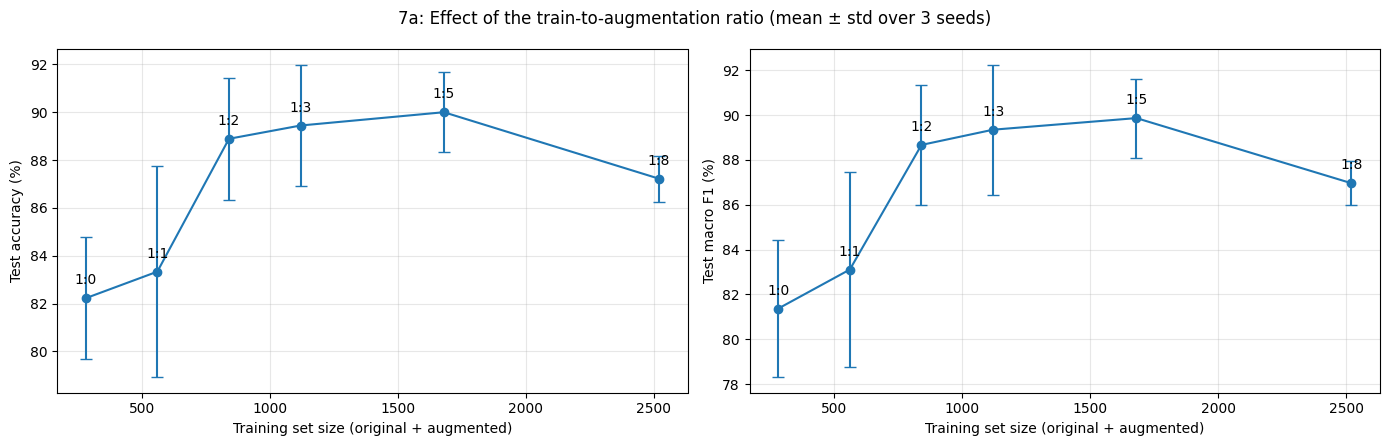

In [70]:
names_a = ['baseline'] + [f'combined_x{k}' for k in RATIOS]
sum_a = summarize(names_a)
display(sum_a.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, col, label in [(ax[0], 'test_acc', 'Test accuracy (%)'), (ax[1], 'f1', 'Test macro F1 (%)')]:
    mean_col = 'test_acc_mean' if col == 'test_acc' else 'f1_mean'
    std_col  = 'test_acc_std'  if col == 'test_acc' else 'f1_std'
    a.errorbar(sum_a['train_size'], sum_a[mean_col] * 100, yerr=sum_a[std_col] * 100,
               marker='o', capsize=4)
    for x, y, r in zip(sum_a['train_size'], sum_a[mean_col] * 100, sum_a['ratio']):
        a.annotate(r, (x, y), textcoords='offset points', xytext=(0, 10), ha='center')
    a.set_xlabel('Training set size (original + augmented)'); a.set_ylabel(label); a.grid(alpha=0.3)
fig.suptitle('7a: Effect of the train-to-augmentation ratio (mean ± std over 3 seeds)')
plt.tight_layout(); plt.show()

### 7.5: 7-b single techniques (1:1)

In [71]:
SINGLE = ['flip', 'rotate', 'crop', 'color', 'blur']
for t in SINGLE:
    run_experiment(f'{t}_x1', t, AUG_POLICIES[t], 1)
# 'combined_x1' was already run in 7a; it is the reference for 7b

Best val acc 0.867 at epoch 47
flip_x1                seed 42: test acc 0.850 | macro F1 0.851 | 1.64 min
Best val acc 0.867 at epoch 42
flip_x1                seed 43: test acc 0.883 | macro F1 0.885 | 1.62 min
Best val acc 0.850 at epoch 30
flip_x1                seed 44: test acc 0.833 | macro F1 0.828 | 1.61 min
Best val acc 0.917 at epoch 49
rotate_x1              seed 42: test acc 0.817 | macro F1 0.812 | 1.62 min
Best val acc 0.883 at epoch 30
rotate_x1              seed 43: test acc 0.817 | macro F1 0.806 | 1.63 min
Best val acc 0.883 at epoch 34
rotate_x1              seed 44: test acc 0.867 | macro F1 0.862 | 1.62 min
Best val acc 0.883 at epoch 47
crop_x1                seed 42: test acc 0.833 | macro F1 0.836 | 1.64 min
Best val acc 0.833 at epoch 45
crop_x1                seed 43: test acc 0.850 | macro F1 0.839 | 1.62 min
Best val acc 0.850 at epoch 44
crop_x1                seed 44: test acc 0.833 | macro F1 0.823 | 1.63 min
Best val acc 0.883 at epoch 50
color_x1       

### 7.6: 7b results, bar chart and per-class F1

,ratio,n_original,n_augmented,train_size,runs,val_acc_mean,test_acc_mean,test_acc_std,f1_mean,f1_std,delta_acc_vs_baseline
experiment,,,,,,,,,,,
baseline,1:0,280,0,280,3,0.8389,0.8222,0.0255,0.8137,0.0305,0.0000
flip_x1,1:1,280,280,560,3,0.8611,0.8556,0.0255,0.8548,0.0286,0.0333
rotate_x1,1:1,280,280,560,3,0.8944,0.8333,0.0289,0.8267,0.0306,0.0111
crop_x1,1:1,280,280,560,3,0.8556,0.8389,0.0096,0.8325,0.0084,0.0167
color_x1,1:1,280,280,560,3,0.8833,0.8556,0.0096,0.8537,0.0134,0.0333
blur_x1,1:1,280,280,560,3,0.8667,0.8278,0.0536,0.8243,0.0509,0.0056
combined_x1,1:1,280,280,560,3,0.8778,0.8333,0.0441,0.8311,0.0433,0.0111


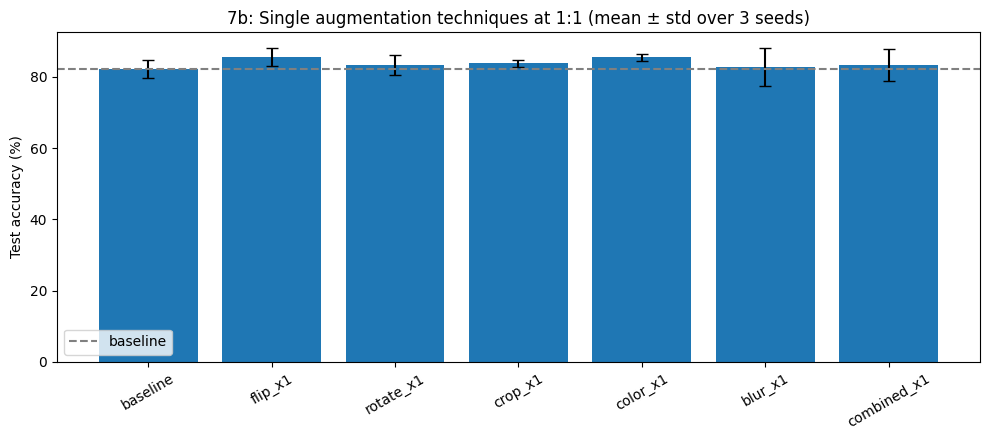

,f1_Daffodil,f1_Daisy,f1_Iris,f1_Sunflower,f1_Tulip
experiment,,,,,
baseline,0.716,0.905,0.881,0.921,0.645
flip_x1,0.759,0.972,0.930,0.877,0.735
rotate_x1,0.702,0.937,0.881,0.946,0.668
crop_x1,0.643,0.935,0.906,0.909,0.770
color_x1,0.702,0.973,0.920,0.919,0.754
blur_x1,0.706,0.947,0.866,0.907,0.697
combined_x1,0.734,0.862,0.917,0.935,0.707


In [72]:
names_b = ['baseline'] + [f'{t}_x1' for t in SINGLE] + ['combined_x1']
sum_b = summarize(names_b)
display(sum_b.round(4))

plt.figure(figsize=(10, 4.5))
plt.bar(sum_b.index, sum_b['test_acc_mean'] * 100, yerr=sum_b['test_acc_std'] * 100, capsize=4)
plt.axhline(sum_b.loc['baseline', 'test_acc_mean'] * 100, ls='--', color='gray', label='baseline')
plt.ylabel('Test accuracy (%)'); plt.xticks(rotation=30); plt.legend()
plt.title('7b: Single augmentation techniques at 1:1 (mean ± std over 3 seeds)')
plt.tight_layout(); plt.show()

# Which technique helps which flower? (mean per-class F1)
per_class_b = (load_results().groupby('experiment')[[f'f1_{c}' for c in class_names]]
               .mean().reindex(names_b))
display(per_class_b.round(3))

### 7.7: 7c, leave-one-out (combined minus one technique, 1:2)

In [73]:
P_APPLY = {'flip': 0.5, 'rotate': 0.5, 'crop': 0.5, 'color': 0.5, 'blur': 0.3}   # same as 'combined'

def make_combined(exclude=None):
    steps = []
    for t, p in P_APPLY.items():
        if t == exclude:
            continue
        steps.append(transforms.RandomHorizontalFlip(p=p) if t == 'flip'
                     else transforms.RandomApply([AUG_POLICIES[t]], p=p))
    return transforms.Compose(steps)

for t in P_APPLY:
    run_experiment(f'combined_no_{t}_x2', f'combined_no_{t}', make_combined(exclude=t), 2)

Best val acc 0.900 at epoch 28
combined_no_flip_x2    seed 42: test acc 0.800 | macro F1 0.780 | 1.8 min
Best val acc 0.867 at epoch 29
combined_no_flip_x2    seed 43: test acc 0.883 | macro F1 0.881 | 1.79 min
Best val acc 0.900 at epoch 47
combined_no_flip_x2    seed 44: test acc 0.833 | macro F1 0.830 | 1.81 min
Best val acc 0.900 at epoch 45
combined_no_rotate_x2  seed 42: test acc 0.833 | macro F1 0.829 | 1.81 min
Best val acc 0.883 at epoch 42
combined_no_rotate_x2  seed 43: test acc 0.883 | macro F1 0.883 | 1.79 min
Best val acc 0.900 at epoch 37
combined_no_rotate_x2  seed 44: test acc 0.850 | macro F1 0.851 | 1.8 min
Best val acc 0.850 at epoch 47
combined_no_crop_x2    seed 42: test acc 0.850 | macro F1 0.845 | 1.82 min
Best val acc 0.867 at epoch 35
combined_no_crop_x2    seed 43: test acc 0.900 | macro F1 0.898 | 1.8 min
Best val acc 0.933 at epoch 49
combined_no_crop_x2    seed 44: test acc 0.933 | macro F1 0.933 | 1.83 min
Best val acc 0.867 at epoch 35
combined_no_color_

### 7.8: 7c Results

,ratio,n_original,n_augmented,train_size,runs,val_acc_mean,test_acc_mean,test_acc_std,f1_mean,f1_std,delta_acc_vs_full
experiment,,,,,,,,,,,
combined_x2,1:2,280,560,840,3,0.8889,0.8889,0.0255,0.8867,0.0266,0.0000
combined_no_flip_x2,1:2,280,560,840,3,0.8889,0.8389,0.0419,0.8304,0.0503,-0.0500
combined_no_rotate_x2,1:2,280,560,840,3,0.8944,0.8556,0.0255,0.8543,0.0271,-0.0333
combined_no_crop_x2,1:2,280,560,840,3,0.8833,0.8944,0.0419,0.8918,0.0446,0.0056
combined_no_color_x2,1:2,280,560,840,3,0.8944,0.8722,0.0255,0.8709,0.0253,-0.0167
combined_no_blur_x2,1:2,280,560,840,3,0.8611,0.8667,0.0289,0.8642,0.0285,-0.0222


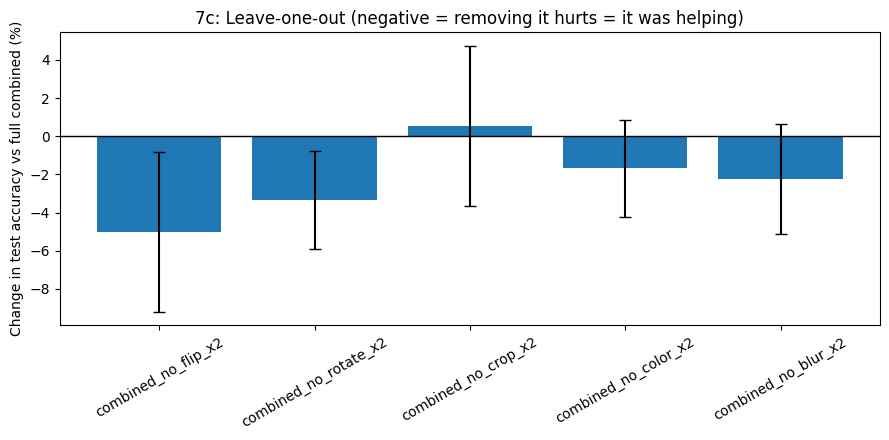

In [74]:
names_c = ['combined_x2'] + [f'combined_no_{t}_x2' for t in P_APPLY]
sum_c = summarize(names_c)
full = sum_c.loc['combined_x2', 'test_acc_mean']
sum_c['delta_acc_vs_full'] = sum_c['test_acc_mean'] - full
display(sum_c.round(4))

plt.figure(figsize=(9, 4.5))
deltas = sum_c['delta_acc_vs_full'].drop('combined_x2') * 100
plt.bar(deltas.index, deltas, yerr=sum_c['test_acc_std'].drop('combined_x2') * 100, capsize=4)
plt.axhline(0, color='black', lw=1)
plt.ylabel('Change in test accuracy vs full combined (%)'); plt.xticks(rotation=30)
plt.title('7c: Leave-one-out (negative = removing it hurts = it was helping)')
plt.tight_layout(); plt.show()

### 7.9: Save to Drive

In [75]:
shutil.copytree(AUG_LOCAL, AUG_DRIVE, dirs_exist_ok=True)
print("Augmented sets on Drive:", sorted(os.listdir(AUG_DRIVE)))
print("Results CSV:", RESULTS_CSV)

Augmented sets on Drive: ['blur_x1', 'color_x1', 'combined_no_blur_x2', 'combined_no_color_x2', 'combined_no_crop_x2', 'combined_no_flip_x2', 'combined_no_rotate_x2', 'combined_x1', 'combined_x2', 'combined_x3', 'combined_x5', 'combined_x8', 'crop_x1', 'flip_x1', 'rotate_x1']
Results CSV: /content/drive/MyDrive/Semester 7/Advanced Machine Learning/Data Augmentation Assignment/results/ablation_results.csv


### 7.10 All individual runs


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

RESULTS_CSV = '/content/drive/MyDrive/Semester 7/Advanced Machine Learning/Data Augmentation Assignment/results/ablation_results.csv'
cols = ['experiment', 'seed', 'ratio', 'n_original', 'n_augmented', 'train_size',
        'best_epoch', 'best_val_acc', 'test_acc', 'test_macro_f1']
pd.read_csv(RESULTS_CSV)[cols].round(4)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,experiment,seed,ratio,n_original,n_augmented,train_size,best_epoch,best_val_acc,test_acc,test_macro_f1
0,baseline,42,1:0,280,0,280,48,0.8333,0.8000,0.7885
1,baseline,43,1:0,280,0,280,30,0.8500,0.8167,0.8050
2,baseline,44,1:0,280,0,280,42,0.8333,0.8500,0.8477
3,combined_x1,42,1:1,280,280,560,31,0.8667,0.8167,0.8151
4,combined_x1,43,1:1,280,280,560,49,0.8833,0.8833,0.8801
5,combined_x1,44,1:1,280,280,560,37,0.8833,0.8000,0.7981
6,combined_x2,42,1:2,280,560,840,39,0.8667,0.8667,0.8638
7,combined_x2,43,1:2,280,560,840,41,0.8667,0.9167,0.9159
8,combined_x2,44,1:2,280,560,840,47,0.9333,0.8833,0.8804
9,combined_x3,42,1:3,280,840,1120,44,0.9167,0.8667,0.8614


# Task 7 answers

(a). Yes. According to the experiments done, the ratio has a strong impact on the model performance.Accuracy increases considerably up to 1:2, followed by a plateau between 1:2 and 1:5, indicating diminishing returns. At 1:8, performance declines slightly. Although 1:5 achieves the highest mean accuracy (90.0%), ratios of 1:2 to 1:3 offer the best trade-off between performance and computational cost.

(b) Horizontal flipping is the most effective augmentation technique, as demonstrated by the results in Figures 7b and 7c. Colour jitter also performs well and provides the most consistent results when applied individually. In contrast, blur and cropping offer the least benefit. Overall, combining multiple augmentation techniques at a higher ratio achieves the best performance.

## Limitations of the Experiment

- **Small test set and limited seeds:** Only three random seeds were used, and the test set contained 60 images. Each image therefore represents approximately 1.67 percentage points of accuracy, meaning that small differences may reflect just one or two images.

- **Unequal training exposure:** All models were trained for 50 epochs, but larger datasets involved more training steps. Consequently, the effects of increased data volume and additional training updates cannot be separated.

- **Single augmentation generation:** Each augmented dataset was generated only once using seed 42. Therefore, the reported variability (±) reflects training randomness rather than variation between independently generated augmented datasets.

- **Fixed model configuration:** The experiments used a single CNN architecture and fixed training settings. Different architectures or hyperparameters might produce different results.